# Retos del workshop RAG · 04_challenges

Este notebook contiene el reto **C1 (HNSW contra fuerza bruta con FAISS)**. No necesita API key: solo FAISS, NumPy y matplotlib.

Los retos que dependen del índice de papers (C3, C4, C5 y C6) están al final del notebook `03_rag_workshop_papers_nvidia_nim_colab.ipynb`, porque reutilizan `vectorstore`, `all_docs` y `rag_chain`.

## C1 · HNSW contra fuerza bruta con FAISS

In [1]:
%pip install -q faiss-cpu matplotlib

In [2]:
import os, time
from pathlib import Path
import faiss
import numpy as np
import matplotlib.pyplot as plt

# Las búsquedas se miden con un solo hilo para que «ms por consulta» sea comparable
# entre el índice exacto y HNSW (la construcción sí usa todos los núcleos).
N_THREADS = faiss.omp_get_max_threads()
EVID = Path("evidencias") if Path("evidencias").exists() else Path("../evidencias")
EVID.mkdir(exist_ok=True)

d, nq, k = 64, 200, 10
M_VALUES = (8, 16, 32)
EF_VALUES = (10, 16, 32, 64, 128, 256)


def recall_at_k(I, I_true):
    return float(np.mean([len(set(a) & set(b)) / len(b) for a, b in zip(I, I_true)]))


def timed_search(index, xq, k):
    faiss.omp_set_num_threads(1)
    t0 = time.perf_counter(); _, I = index.search(xq, k); dt = time.perf_counter() - t0
    faiss.omp_set_num_threads(N_THREADS)
    return I, dt / len(xq) * 1000


def exact(xb, xq, k):
    flat = faiss.IndexFlatL2(xb.shape[1]); flat.add(xb)
    I, ms = timed_search(flat, xq, k)
    return I, ms


def hnsw(xb, M, ef_construction=100):
    index = faiss.IndexHNSWFlat(xb.shape[1], M)
    index.hnsw.efConstruction = ef_construction
    t0 = time.perf_counter(); index.add(xb); build_s = time.perf_counter() - t0
    return index, build_s

print("hilos disponibles:", N_THREADS)

hilos disponibles: 4


### Experimento 1 · Barrido de M y efSearch con n = 20 000 (datos uniformes)

In [3]:
rng = np.random.default_rng(42)
n = 20_000
xb = rng.random((n, d), dtype="float32")
xq = rng.random((nq, d), dtype="float32")

I_true, t_flat = exact(xb, xq, k)
rows = []
for M in M_VALUES:
    index, build_s = hnsw(xb, M)
    for ef in EF_VALUES:
        index.hnsw.efSearch = ef
        I, ms = timed_search(index, xq, k)
        rows.append(dict(M=M, ef=ef, recall=recall_at_k(I, I_true), ms=ms, build=build_s))

print(f"exacto (IndexFlatL2): {t_flat:.3f} ms/consulta\n")
print("| M | efSearch | recall@10 | ms/consulta | construcción (s) |")
print("|---:|---:|---:|---:|---:|")
for r in rows:
    print(f"| {r['M']} | {r['ef']} | {r['recall']:.3f} | {r['ms']:.3f} | {r['build']:.2f} |")

exacto (IndexFlatL2): 0.186 ms/consulta

| M | efSearch | recall@10 | ms/consulta | construcción (s) |
|---:|---:|---:|---:|---:|
| 8 | 10 | 0.168 | 0.017 | 0.60 |
| 8 | 16 | 0.242 | 0.024 | 0.60 |
| 8 | 32 | 0.355 | 0.044 | 0.60 |
| 8 | 64 | 0.510 | 0.075 | 0.60 |
| 8 | 128 | 0.683 | 0.150 | 0.60 |
| 8 | 256 | 0.819 | 0.241 | 0.60 |
| 16 | 10 | 0.329 | 0.016 | 0.84 |
| 16 | 16 | 0.425 | 0.022 | 0.84 |
| 16 | 32 | 0.599 | 0.041 | 0.84 |
| 16 | 64 | 0.770 | 0.072 | 0.84 |
| 16 | 128 | 0.905 | 0.135 | 0.84 |
| 16 | 256 | 0.971 | 0.293 | 0.84 |
| 32 | 10 | 0.468 | 0.027 | 1.06 |
| 32 | 16 | 0.579 | 0.042 | 1.06 |
| 32 | 32 | 0.761 | 0.082 | 1.06 |
| 32 | 64 | 0.909 | 0.155 | 1.06 |
| 32 | 128 | 0.983 | 0.227 | 1.06 |
| 32 | 256 | 0.998 | 0.426 | 1.06 |


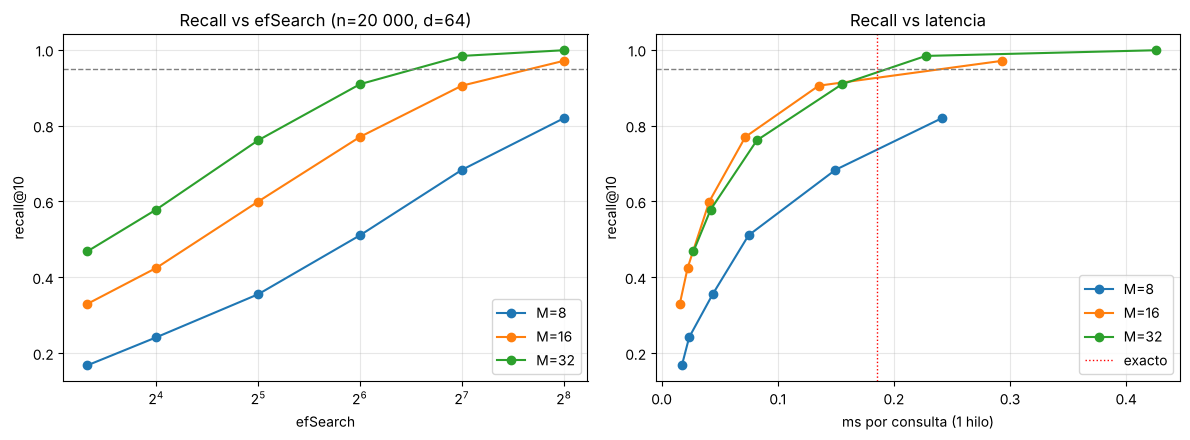

efSearch mínimo para recall ≥ 0.95 con M=16: 256


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for M in M_VALUES:
    sub = [r for r in rows if r["M"] == M]
    axes[0].plot([r["ef"] for r in sub], [r["recall"] for r in sub], marker="o", label=f"M={M}")
    axes[1].plot([r["ms"] for r in sub], [r["recall"] for r in sub], marker="o", label=f"M={M}")
axes[0].set_xscale("log", base=2); axes[0].set_xlabel("efSearch"); axes[0].set_ylabel("recall@10")
axes[0].axhline(0.95, ls="--", c="gray", lw=1); axes[0].set_title("Recall vs efSearch (n=20 000, d=64)")
axes[1].axvline(t_flat, ls=":", c="red", lw=1, label="exacto")
axes[1].set_xlabel("ms por consulta (1 hilo)"); axes[1].set_ylabel("recall@10")
axes[1].axhline(0.95, ls="--", c="gray", lw=1); axes[1].set_title("Recall vs latencia")
for ax in axes: ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(EVID / "C1_recall.png", dpi=120); plt.show()

ok = [r for r in rows if r["M"] == 16 and r["recall"] >= 0.95]
print("efSearch mínimo para recall ≥ 0.95 con M=16:", ok[0]["ef"] if ok else "ninguno en el barrido")

### Experimento 2 · ¿Desde qué n HNSW es más rápido que el exacto? (M = 16)

In [5]:
scale_rows = []
for n in (20_000, 100_000, 500_000):
    rng = np.random.default_rng(n)
    xb = rng.random((n, d), dtype="float32"); xq = rng.random((nq, d), dtype="float32")
    I_true, t_flat = exact(xb, xq, k)
    index, build_s = hnsw(xb, 16)
    for ef in (64, 128, 256):
        index.hnsw.efSearch = ef
        I, ms = timed_search(index, xq, k)
        scale_rows.append(dict(n=n, ef=ef, exact_ms=t_flat, hnsw_ms=ms,
                               recall=recall_at_k(I, I_true), build=build_s))
    del index, xb

print("| n | efSearch | exacto ms/q | HNSW ms/q | aceleración | recall@10 | construcción HNSW (s) |")
print("|---:|---:|---:|---:|---:|---:|---:|")
for r in scale_rows:
    print(f"| {r['n']:,} | {r['ef']} | {r['exact_ms']:.3f} | {r['hnsw_ms']:.3f} | "
          f"{r['exact_ms']/r['hnsw_ms']:.1f}× | {r['recall']:.3f} | {r['build']:.1f} |")

| n | efSearch | exacto ms/q | HNSW ms/q | aceleración | recall@10 | construcción HNSW (s) |
|---:|---:|---:|---:|---:|---:|---:|
| 20,000 | 64 | 0.201 | 0.105 | 1.9× | 0.776 | 0.9 |
| 20,000 | 128 | 0.201 | 0.146 | 1.4× | 0.910 | 0.9 |
| 20,000 | 256 | 0.201 | 0.301 | 0.7× | 0.970 | 0.9 |
| 100,000 | 64 | 1.798 | 0.190 | 9.5× | 0.528 | 5.9 |
| 100,000 | 128 | 1.798 | 0.307 | 5.9× | 0.713 | 5.9 |
| 100,000 | 256 | 1.798 | 0.639 | 2.8× | 0.848 | 5.9 |
| 500,000 | 64 | 14.610 | 0.339 | 43.1× | 0.340 | 45.1 |
| 500,000 | 128 | 14.610 | 0.543 | 26.9× | 0.492 | 45.1 |
| 500,000 | 256 | 14.610 | 0.961 | 15.2× | 0.634 | 45.1 |


### Experimento 3 · ¿Por qué los datos aleatorios son un caso difícil?

Comparo los datos uniformes con datos agrupados (mezcla de 50 gaussianas en un subespacio de 8 dimensiones incrustado en 64), que se parecen más a embeddings de texto reales: tienen estructura de clusters y una dimensión intrínseca baja.

In [6]:
def make_clustered(d=64, n_clusters=50, intrinsic=8, seed=0):
    """Devuelve un muestreador de una mezcla de gaussianas en un subespacio de 8 dimensiones."""
    rng = np.random.default_rng(seed)
    basis = np.linalg.qr(rng.normal(size=(d, intrinsic)))[0].T          # 8 direcciones en R^64
    centers = rng.normal(size=(n_clusters, intrinsic)) * 3
    def sample(n, seed):
        r = np.random.default_rng(seed)
        z = centers[r.integers(0, n_clusters, n)] + r.normal(size=(n, intrinsic))
        return (z @ basis + 0.05 * r.normal(size=(n, d))).astype("float32")
    return sample

n = 20_000
sample = make_clustered()
datasets = {
    "uniforme": (np.random.default_rng(1).random((n, d), dtype="float32"),
                 np.random.default_rng(2).random((nq, d), dtype="float32")),
    # base y consultas salen de la misma distribución, pero con semillas distintas
    "agrupado": (sample(n, seed=1), sample(nq, seed=2)),
}
cmp_rows = []
for name, (xb, xq) in datasets.items():
    I_true, _ = exact(xb, xq, k)
    index, _ = hnsw(xb, 16)
    for ef in (10, 16, 32, 64):
        index.hnsw.efSearch = ef
        I, _ = timed_search(index, xq, k)
        cmp_rows.append((name, ef, recall_at_k(I, I_true)))

print("| datos | efSearch | recall@10 (M=16) |")
print("|---|---:|---:|")
for name, ef, rec in cmp_rows:
    print(f"| {name} | {ef} | {rec:.3f} |")

| datos | efSearch | recall@10 (M=16) |
|---|---:|---:|
| uniforme | 10 | 0.309 |
| uniforme | 16 | 0.411 |
| uniforme | 32 | 0.607 |
| uniforme | 64 | 0.792 |
| agrupado | 10 | 0.966 |
| agrupado | 16 | 0.990 |
| agrupado | 32 | 0.998 |
| agrupado | 64 | 1.000 |
